# Tarea 2 — Punto 2: análisis de cebada

Este cuaderno desarrolla en orden los apartados del punto 2 con `cebada.dat`: exploración descriptiva, ajuste por cuasi-verosimilitud y discusión de la regresión Simplex. Incluye explicaciones de las fórmulas y verificaciones numéricas para reproducir el procedimiento.

> Ejecuta las celdas en orden. El archivo `cebada.dat` debe estar en el directorio de trabajo del cuaderno. La respuesta `area` es una proporción entre 0 y 1.

## 1. Preparación del entorno

Se usan NumPy y pandas para los cálculos y la manipulación de datos, Matplotlib y Seaborn para las gráficas, y `expit` de SciPy para calcular de forma estable la función logística. Si falta una dependencia, la celda muestra el comando para instalarla en el mismo Python que utiliza el kernel.

In [1]:
import sys
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.special import expit
except ModuleNotFoundError as error:
    print(f"Falta instalar una dependencia: {error}")
    print(f'En PowerShell ejecuta: "{sys.executable}" -m pip install numpy pandas scipy matplotlib seaborn')
    raise

sns.set_theme(style="whitegrid", palette="muted")
print(f"Python del kernel: {sys.executable}")
print(f"Directorio de trabajo: {Path.cwd()}")

Python del kernel: c:\Users\PERSONAL\AppData\Local\Programs\Python\Python314\python.exe
Directorio de trabajo: d:\Escritorio_D\Tarea_2_MLG


## 2. Carga y validación de los datos

El archivo tiene tres columnas sin encabezado: proporción afectada (`area`), lugar y variedad. Antes de modelar, se comprueba que los datos se cargaron, que no hay valores faltantes y que la respuesta está en el intervalo [0, 1]. Estas verificaciones ayudan a detectar problemas de ruta o formato antes de continuar.

In [2]:
ruta_datos = Path("cebada.dat")
if not ruta_datos.is_file():
    raise FileNotFoundError(
        f"No se encontró {ruta_datos.resolve()}. "
        "Coloca cebada.dat en el directorio de trabajo del cuaderno."
    )

cebada = pd.read_csv(
    ruta_datos,
    sep=r"\s+",
    header=None,
    names=["area", "lugar", "variedad"],
)

if cebada.empty:
    raise ValueError("cebada.dat no contiene observaciones.")
if cebada.isna().any().any():
    raise ValueError("Hay valores faltantes en cebada.dat; revisa el formato del archivo.")
if not cebada["area"].between(0, 1).all():
    raise ValueError("La variable area debe ser una proporción entre 0 y 1.")

print(f"Número de observaciones: {len(cebada)}")
print(f"Lugares: {sorted(cebada['lugar'].unique())}")
print(f"Variedades: {sorted(cebada['variedad'].unique())}")
display(cebada.head())
display(cebada.describe().T)

Número de observaciones: 90
Lugares: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Variedades: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,area,lugar,variedad
0,0.0005,1,1
1,0.0000,1,2
2,0.0000,1,3
3,0.0010,1,4
4,0.0025,1,5


,count,mean,std,min,25%,50%,75%,max
area,90.0,0.207172,0.276461,0.0,0.0125,0.05,0.355,0.95
lugar,90.0,5.000000,2.596454,1.0,3.0000,5.00,7.000,9.00
variedad,90.0,5.500000,2.888373,1.0,3.0000,5.50,8.000,10.00


## 3. Apartado (a): análisis descriptivo y boxplots

Se resumen la cantidad de observaciones, media, mediana, desviación estándar, mínimo y máximo de `area` por lugar y por variedad. Los boxplots muestran mediana, cuartiles y observaciones extremas. Son una exploración descriptiva: por sí solos no demuestran que las diferencias entre grupos sean estadísticamente significativas.

Resumen por lugar


,n,media,mediana,desviacion,minimo,maximo
lugar,,,,,,
1,10,0.0052,0.0018,0.0065,0.0000,0.015
2,10,0.0256,0.0052,0.0425,0.0000,0.127
3,10,0.1104,0.0250,0.1323,0.0000,0.375
4,10,0.1335,0.0275,0.1976,0.0001,0.550
5,10,0.1337,0.0700,0.1410,0.0100,0.435
6,10,0.1660,0.0500,0.2499,0.0100,0.750
7,10,0.2751,0.1750,0.2658,0.0010,0.750
8,10,0.4000,0.3750,0.3300,0.0500,0.750
9,10,0.6150,0.5625,0.3132,0.1750,0.950


Resumen por variedad


,n,media,mediana,desviacion,minimo,maximo
variedad,,,,,,
1,9,0.0420,0.0250,0.0544,0.0000,0.175
2,9,0.0477,0.0100,0.0828,0.0000,0.250
3,9,0.0734,0.0500,0.1341,0.0000,0.425
4,9,0.0957,0.0500,0.1596,0.0010,0.500
5,9,0.1400,0.0250,0.1875,0.0025,0.500
6,9,0.2176,0.0500,0.3637,0.0001,0.950
7,9,0.2418,0.1658,0.2412,0.0000,0.625
8,9,0.3481,0.2500,0.3307,0.0130,0.950
9,9,0.3722,0.3750,0.3357,0.0100,0.950


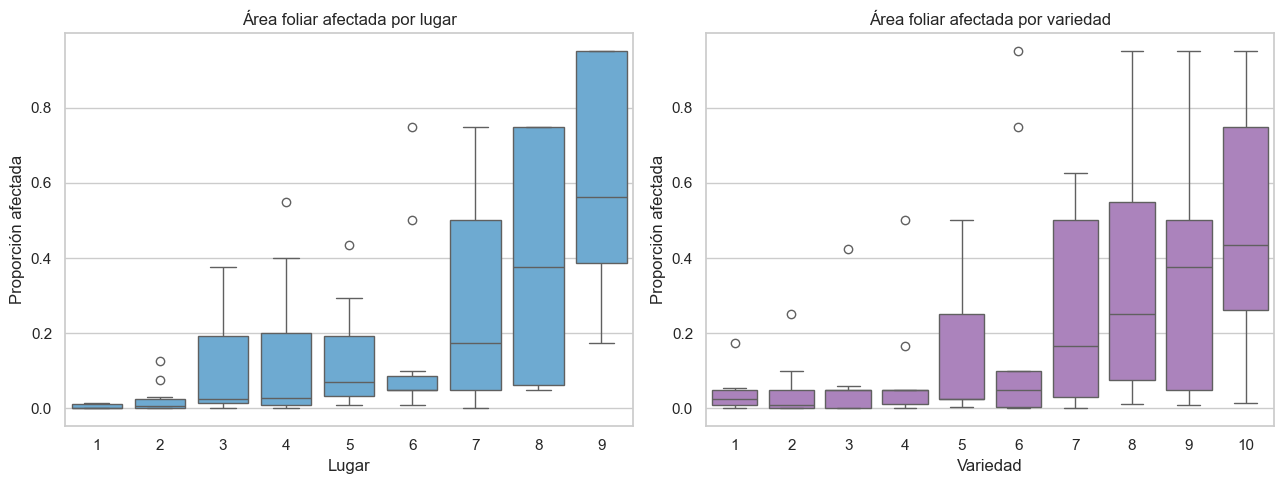

Figura guardada como fig_cebada_boxplots.png


In [3]:
resumen = {
    "n": "size",
    "media": "mean",
    "mediana": "median",
    "desviacion": "std",
    "minimo": "min",
    "maximo": "max",
}

print("Resumen por lugar")
display(cebada.groupby("lugar")["area"].agg(**resumen).round(4))
print("Resumen por variedad")
display(cebada.groupby("variedad")["area"].agg(**resumen).round(4))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=cebada, x="lugar", y="area", color="#5DADE2", ax=ejes[0])
ejes[0].set(title="Área foliar afectada por lugar", xlabel="Lugar", ylabel="Proporción afectada")
sns.boxplot(data=cebada, x="variedad", y="area", color="#AF7AC5", ax=ejes[1])
ejes[1].set(title="Área foliar afectada por variedad", xlabel="Variedad", ylabel="Proporción afectada")
plt.tight_layout()
plt.savefig("fig_cebada_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()
print("Figura guardada como fig_cebada_boxplots.png")

## 4. Apartado (b): ajuste por cuasi-verosimilitud

Se usa el modelo aditivo `logit(mu) = X beta`, con intercepto y variables indicadoras para lugar y variedad. El primer nivel de cada factor es la referencia; por eso se omite una columna indicadora por factor.

Para una media `mu = logistic(eta)`, la derivada es `d mu / d eta = mu(1-mu)`. En cada iteración de mínimos cuadrados ponderados se calcula la respuesta de trabajo `z = eta + (y-mu)/(d mu/d eta)` y el peso `w = (d mu/d eta)^2 / V(mu)`. Así, para `V1(mu)=mu(1-mu)`, el peso es `mu(1-mu)`; para `V2(mu)=[mu(1-mu)]^2`, el peso es 1.

La dispersión se estima con los residuos de Pearson: `X2 = sum((y-mu)^2/V(mu))` y `phi = X2/(n-p)`, donde `p` es el rango de la matriz de diseño. Como estos son modelos de cuasi-verosimilitud, no se usa AIC para compararlos.

In [4]:
# Codificar factores con una categoría de referencia para cada uno.
X_lugar = pd.get_dummies(cebada["lugar"], prefix="lugar", drop_first=True, dtype=float)
X_variedad = pd.get_dummies(cebada["variedad"], prefix="variedad", drop_first=True, dtype=float)
X = np.column_stack([np.ones(len(cebada)), X_lugar.to_numpy(), X_variedad.to_numpy()])
y = cebada["area"].to_numpy(dtype=float)

rango_X = np.linalg.matrix_rank(X)
grados_libertad = len(y) - rango_X
if grados_libertad <= 0:
    raise ValueError("No hay grados de libertad residuales para estimar la dispersión.")
if rango_X < X.shape[1]:
    raise ValueError("La matriz de diseño no tiene rango completo; revisa los niveles de los factores.")

print(f"Dimensiones de X: {X.shape}; rango: {rango_X}; grados de libertad residuales: {grados_libertad}")
print("Primeras columnas de la matriz de diseño:", ["intercepto", *X_lugar.columns, *X_variedad.columns][:8])

def ajustar_cuasi(X, y, tipo_varianza, max_iter=200, tolerancia=1e-8):
    """Ajusta un modelo logit por mínimos cuadrados ponderados iterativos."""
    n, p_columnas = X.shape
    y_inicio = np.clip(y, 1e-6, 1 - 1e-6)
    eta_inicio = np.log(y_inicio / (1 - y_inicio))
    beta = np.linalg.lstsq(X, eta_inicio, rcond=None)[0]
    convergio = False

    for iteracion in range(1, max_iter + 1):
        eta = X @ beta
        mu = np.clip(expit(eta), 1e-8, 1 - 1e-8)
        derivada = mu * (1 - mu)
        varianza = derivada if tipo_varianza == "v1" else derivada**2
        z = eta + (y - mu) / derivada
        pesos = derivada**2 / varianza
        raiz_pesos = np.sqrt(pesos)
        X_ponderada = X * raiz_pesos[:, None]
        z_ponderada = z * raiz_pesos
        beta_nuevo = np.linalg.lstsq(X_ponderada, z_ponderada, rcond=None)[0]

        if np.max(np.abs(beta_nuevo - beta)) <= tolerancia * (1 + np.max(np.abs(beta))):
            beta = beta_nuevo
            convergio = True
            break
        beta = beta_nuevo

    mu = np.clip(expit(X @ beta), 1e-8, 1 - 1e-8)
    derivada = mu * (1 - mu)
    varianza = derivada if tipo_varianza == "v1" else derivada**2
    residuos_pearson = (y - mu) / np.sqrt(varianza)
    chi_cuadrado = float(np.sum(residuos_pearson**2))
    df_resid = n - np.linalg.matrix_rank(X)

    return {
        "beta": beta,
        "mu": mu,
        "residuos_pearson": residuos_pearson,
        "X2": chi_cuadrado,
        "phi": chi_cuadrado / df_resid,
        "iteraciones": iteracion,
        "convergio": convergio,
    }


Dimensiones de X: (90, 18); rango: 18; grados de libertad residuales: 72
Primeras columnas de la matriz de diseño: ['intercepto', 'lugar_2', 'lugar_3', 'lugar_4', 'lugar_5', 'lugar_6', 'lugar_7', 'lugar_8']


In [5]:
modelo_v1 = ajustar_cuasi(X, y, "v1")
modelo_v2 = ajustar_cuasi(X, y, "v2")

tabla_ajustes = pd.DataFrame(
    [
        {"funcion de varianza": "V1(mu) = mu(1-mu)", "X2 Pearson": modelo_v1["X2"], "gl residuales": grados_libertad, "phi": modelo_v1["phi"], "iteraciones": modelo_v1["iteraciones"], "convergio": modelo_v1["convergio"]},
        {"funcion de varianza": "V2(mu) = [mu(1-mu)]^2", "X2 Pearson": modelo_v2["X2"], "gl residuales": grados_libertad, "phi": modelo_v2["phi"], "iteraciones": modelo_v2["iteraciones"], "convergio": modelo_v2["convergio"]},
    ]
)
display(tabla_ajustes.round(6))

if not modelo_v1["convergio"] or not modelo_v2["convergio"]:
    print("Advertencia: al menos un ajuste alcanzó el máximo de iteraciones sin cumplir la tolerancia.")

,funcion de varianza,X2 Pearson,gl residuales,phi,iteraciones,convergio
0,V1(mu) = mu(1-mu),6.392228,72,0.088781,6,True
1,V2(mu) = [mu(1-mu)]^2,71.170251,72,0.988476,23,True


### Demostración breve de los pesos

Para una media ilustrativa `mu=0.2`, la derivada logística es `0.2(1-0.2)=0.16`. Entonces el peso de V1 es `0.16^2/0.16=0.16`, mientras que el peso de V2 es `0.16^2/0.16^2=1`. El siguiente bloque verifica esas igualdades numéricamente. Esta demostración ilustra las fórmulas; el ajuste usa las medias estimadas de cada observación.

In [6]:
mu_ejemplo = 0.2
derivada_ejemplo = mu_ejemplo * (1 - mu_ejemplo)
peso_v1 = derivada_ejemplo**2 / derivada_ejemplo
peso_v2 = derivada_ejemplo**2 / derivada_ejemplo**2
print(f"Derivada dmu/deta = {derivada_ejemplo:.2f}")
print(f"Peso con V1 = {peso_v1:.2f} (debe ser mu(1-mu) = {derivada_ejemplo:.2f})")
print(f"Peso con V2 = {peso_v2:.2f} (debe ser 1)")
assert np.isclose(peso_v1, derivada_ejemplo)
assert np.isclose(peso_v2, 1.0)

Derivada dmu/deta = 0.16
Peso con V1 = 0.16 (debe ser mu(1-mu) = 0.16)
Peso con V2 = 1.00 (debe ser 1)


## 5. Apartado (c): posibilidad de ajustar una regresión Simplex

La distribución Simplex estándar tiene soporte en el intervalo abierto (0, 1). En la expresión de devianza usada para este modelo aparece un factor `y(1-y)` en el denominador. Si una observación es exactamente `y=0`, ese denominador se anula; para una media predicha interior `0<mu<1`, el numerador `(y-mu)^2` es positivo y la devianza diverge. Por lo tanto, el ajuste Simplex directo no está definido para estas observaciones de frontera.

La comprobación siguiente cuenta los ceros sin modificar ni eliminar datos. No se añade una constante ni se transforman los valores: eso cambiaría el análisis solicitado y requeriría una justificación metodológica aparte.

In [7]:
n_ceros = int((y == 0).sum())
print(f"Observaciones con area = 0: {n_ceros}")
print("¿Todos los valores están estrictamente entre 0 y 1?", bool(((y > 0) & (y < 1)).all()))

mu_ejemplo = 0.2
numerador_en_cero = (0 - mu_ejemplo) ** 2
denominador_en_cero = 0 * (1 - 0) * mu_ejemplo**2 * (1 - mu_ejemplo)**2
print(f"Ejemplo con y=0 y mu={mu_ejemplo}: numerador={numerador_en_cero}, denominador={denominador_en_cero}")
print("El cociente no es finito; no se puede evaluar la devianza Simplex estándar en y=0.")

Observaciones con area = 0: 4
¿Todos los valores están estrictamente entre 0 y 1? False
Ejemplo con y=0 y mu=0.2: numerador=0.04000000000000001, denominador=0.0
El cociente no es finito; no se puede evaluar la devianza Simplex estándar en y=0.


## 6. Conclusiones del punto 2

- Los resúmenes y boxplots describen cómo varía el área foliar afectada por lugar y variedad.
- Los dos modelos de cuasi-verosimilitud comparten el predictor logit y la matriz de diseño, pero especifican distintas funciones de varianza. Por eso sus estadísticos de Pearson y dispersiones se interpretan bajo sus respectivas especificaciones.
- El ajuste Simplex directo no es apropiado con los ceros observados porque su soporte es abierto y la expresión de devianza se vuelve singular en la frontera. Los ceros se conservan; cualquier estrategia alternativa debe justificarse por separado.

Los valores numéricos del resumen y los ajustes aparecen al ejecutar las celdas con el archivo de datos original.